In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf
from statsmodels.tsa.filters.hp_filter import hpfilter
import warnings
from scipy.sparse import SparseEfficiencyWarning
warnings.simplefilter("ignore", SparseEfficiencyWarning)

from Functions import run_multistart, plot_predictive_density, compute_bimodality_series, plot_bimodality, plot_bimodality_and_series, shock_analysis, plot_predictive_density_ax, plot_bimodality_and_series_2
from MLE_Predictive_Density import neg_loglik_student_mar, neg_loglik_student_marx, mar_studentt_pred_density, marx_studentt_pred_density


In [2]:
# Linear Trend of Volatility Scaling Function 

def linear_vol_scale(price, window=12):

    price = price.dropna()


    # -------------------------
    # Smooth variance 
    # -------------------------
    var_smooth = price.pow(2).ewm(span=window, adjust=False).mean()

    # -------------------------
    # Clean NaNs
    # -------------------------
    var_smooth = var_smooth.dropna()

    # -------------------------
    # Fit linear trend on LOG variance 
    # -------------------------
    log_var = np.log(var_smooth.values + 1e-8)

    t = np.arange(len(log_var))
    slope, intercept = np.polyfit(t, log_var, 1)

    log_var_trend = intercept + slope * t

    # Back to variance (guaranteed positive)
    var_trend = np.exp(log_var_trend)

    var_trend = pd.Series(var_trend, index=var_smooth.index)

    # -------------------------
    # Volatility
    # -------------------------
    vol = np.sqrt(var_trend)

    # safety floor (extra robustness)
    vol = vol.clip(lower=1e-8)

    return vol

### Import Nickel and detrend series with HP filter + linear trend of the volatility scaling

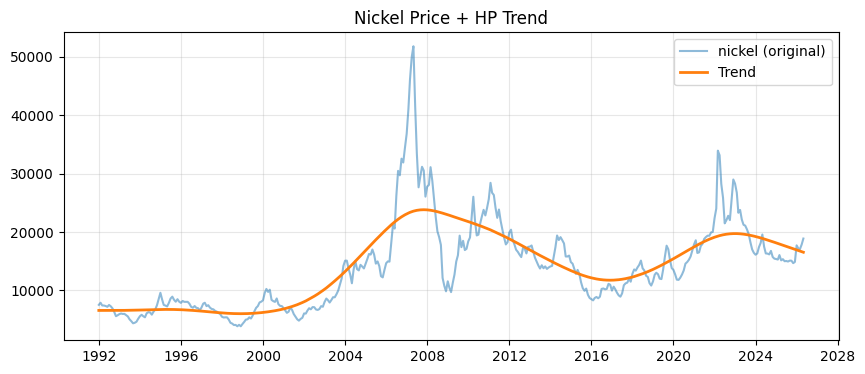

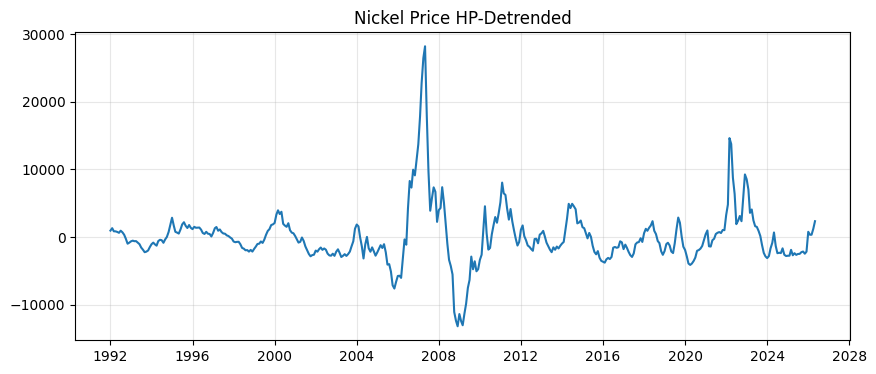

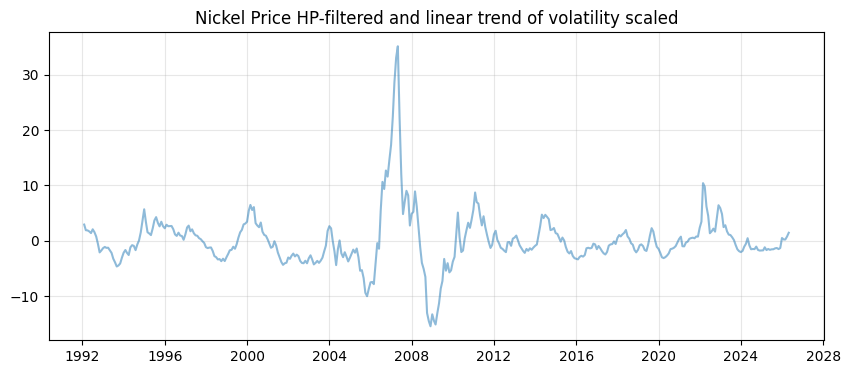

In [3]:
# -------------------------
# DATA
# -------------------------
df_nickel = pd.read_csv("PNICKUSDM.csv", parse_dates=["observation_date"])
df_nickel = df_nickel.dropna().set_index("observation_date")


# HP filter + linear trend of the volatility scaling
cycle, trend = hpfilter(df_nickel["PNICKUSDM"], lamb=129600)

df_nickel["nickel_cycle"] = cycle
df_nickel["nickel_trend"] = trend


nickel_diff = (df_nickel["nickel_cycle"]).diff().dropna()
nickel_sigma = linear_vol_scale(nickel_diff)


df_nickel["nickel_scaled_cycle"]= df_nickel["nickel_cycle"]/nickel_sigma



# Plot trend decomposition
plt.figure(figsize=(10,4))
plt.plot(df_nickel.index, df_nickel["PNICKUSDM"], label="nickel (original)", alpha=0.5)
plt.plot(df_nickel.index, df_nickel["nickel_trend"], label="Trend", linewidth=2)
plt.title("Nickel Price + HP Trend")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Plot cycle 
plt.figure(figsize=(10,4))
plt.plot(df_nickel.index, df_nickel["nickel_cycle"])
plt.title("Nickel Price HP-Detrended")
plt.grid(True, alpha=0.3)
plt.show()

# Plot scaled cycle
plt.figure(figsize=(10,4))
plt.plot(df_nickel.index, df_nickel["nickel_scaled_cycle"], alpha=0.5)
plt.title("Nickel Price HP-filtered and linear trend of volatility scaled")
plt.grid(True, alpha=0.3)
plt.show()



### Extract and Transform Data for Exogeous Variables

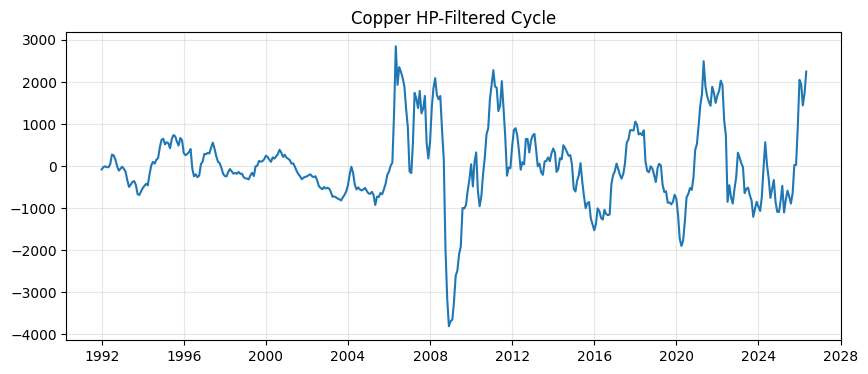

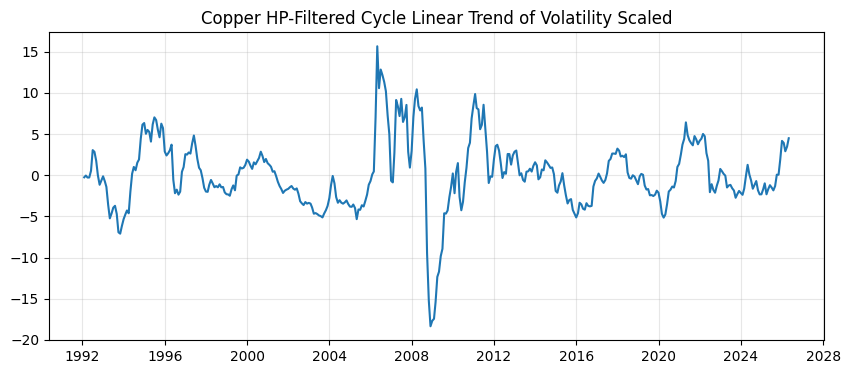

In [4]:
# -------------------------
# Copper
# -------------------------
df_copper = pd.read_csv("PCOPPUSDM.csv", parse_dates=["observation_date"])
df_copper = df_copper.dropna().set_index("observation_date")


# HP filter + linear trend of the volatility scaling
copper_cycle, trend = hpfilter(df_copper, lamb=129600)

copper_diff = (copper_cycle).diff().dropna()
copper_sigma = linear_vol_scale(copper_diff)

copper= copper_cycle/copper_sigma


# Plot cyclical component
plt.figure(figsize=(10,4))
plt.plot(copper_cycle)
plt.title("Copper HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

# Plot cyclical scaled component
plt.figure(figsize=(10,4))
plt.plot(copper)
plt.title("Copper HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

In [5]:
# Data and Parameters 
df = pd.concat(
    [
        df_nickel["nickel_scaled_cycle"], copper
    ],
    axis=1
).dropna()

df.columns = ["nickel_scaled_cycle", "copper"]
df = df.sort_index()

start_date = "1992-03-01"
end_date   = "2026-03-01"

df = df.loc[start_date:end_date].dropna()

y = df["nickel_scaled_cycle"].values
X = df[["copper"]].values

var = ["copper"]

print(f"Aligned sample: {len(y)} monthly observations")
print(f"Date range: {df.index.min().date()} to {df.index.max().date()}")

t1=202 # point to calculate predictive density

#Define Grid for all experiments
grid_min=-60
grid_max=60
ngrid=2000
grid = np.linspace(grid_min, grid_max, ngrid)

#Define points where to calculate bimodality for all experiments
min_t = 2
max_t = len(y) 
times = np.arange(min_t, max_t)


#Parameters for effect of exogenous regressors on bimodality 
std=10
values=30

prominence = 0.01
y_limits=(-25, 40)

Aligned sample: 409 monthly observations
Date range: 1992-03-01 to 2026-03-01


In [6]:
# Get PSY data

import pickle

with open("psy_nickel.pkl", "rb") as f:
    psy = pickle.load(f)

----
## MAR(1,1) with Student-t innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -638.6010251637251

Estimated parameters:
phi             =     0.6221 (0.0361)
psi             =     0.7460 (0.0375)
sigma           =     0.6527 (0.0476)
nu              =     1.8822 (0.2360)

Hessian condition number:
98.23764138690468

Eigenvalues of Hessian:
[1734.664619    469.67843642  737.33627031   17.65784067]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -638.601025
AIC:            1285.202050
BIC:            1301.237303
R^2:            0.907535

Autocorrelation tests (standardized residuals):
  n       = 407
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 0.421989, p-value = 0.515946
    lag  5: statistic = 8.646269, p-value = 0.124033
    lag 10: statistic = 17.522906, p-value = 0.0635649
    lag 20: statistic = 29.973285, p-value = 0.0702877

Autocorrelation tests (squared standardized residuals):
  n       = 407
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 

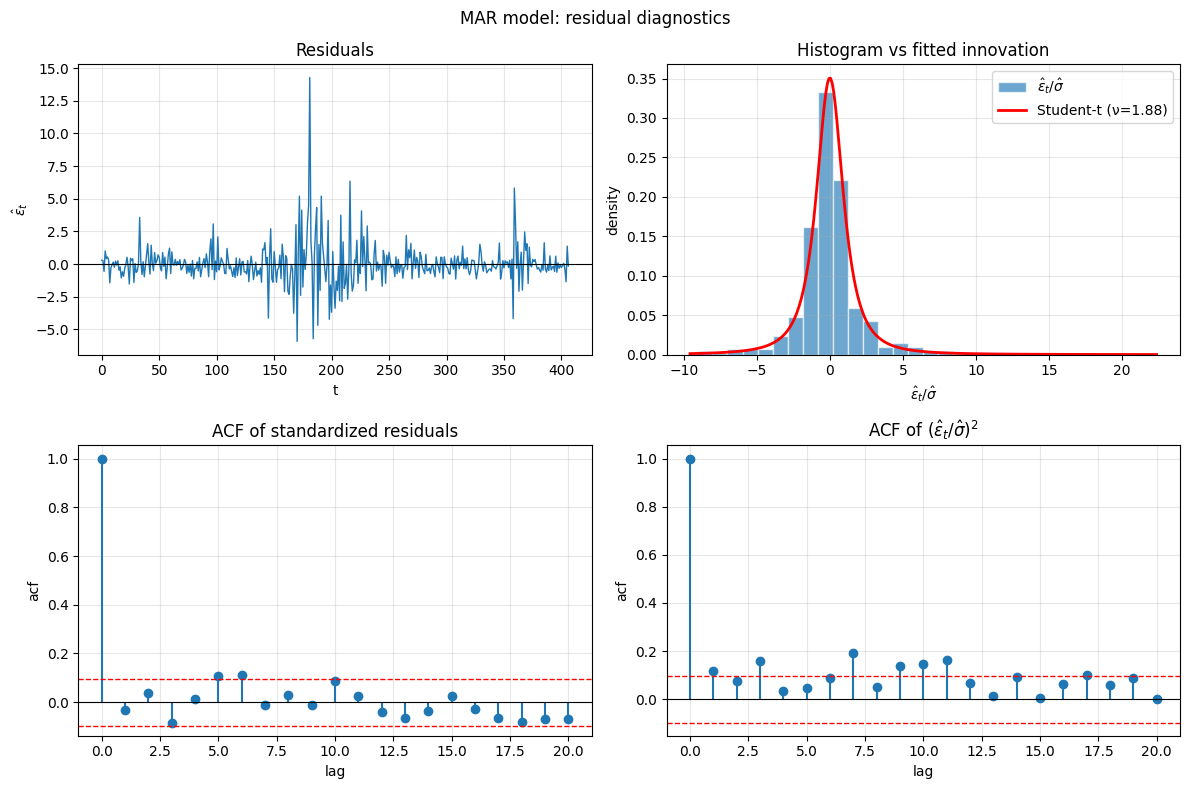

In [7]:
#MLE student-t

param_names = [ "phi", "psi", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None),
    (0.1, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_mar,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

### Predictive Density

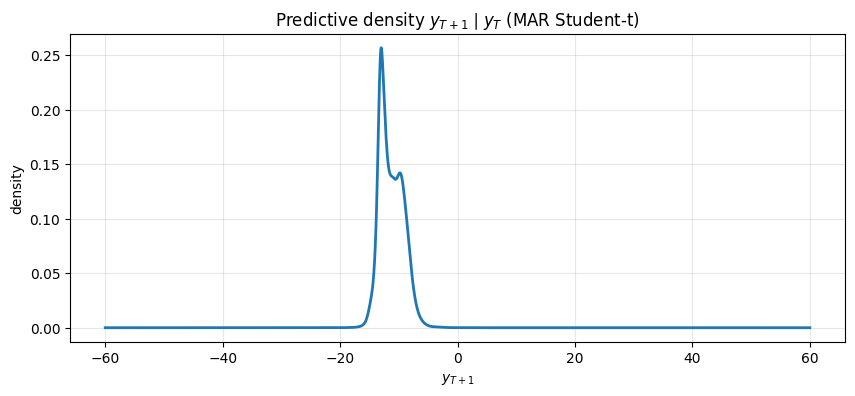

In [8]:
dens = plot_predictive_density(
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid,
    y=y,
    t=t1,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR Student-t)")

### Bimodality

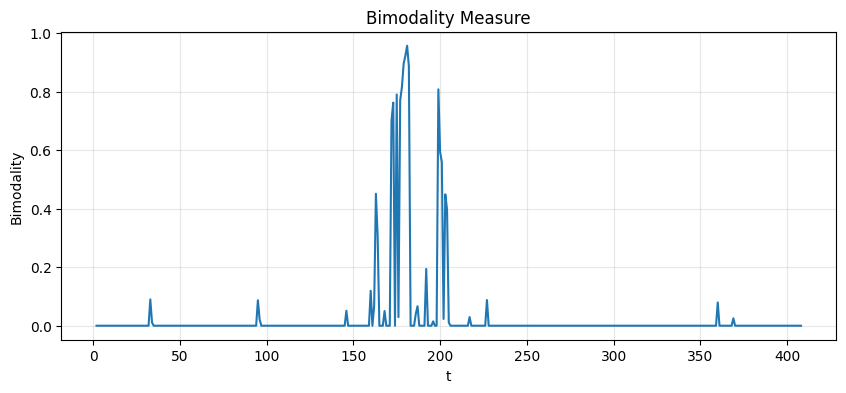

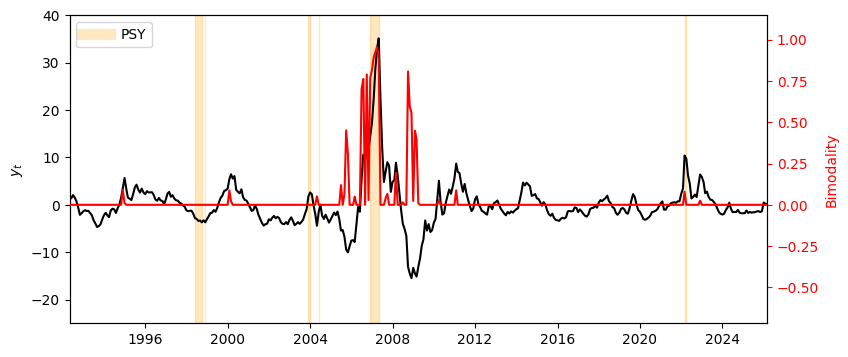

In [9]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_studentt_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


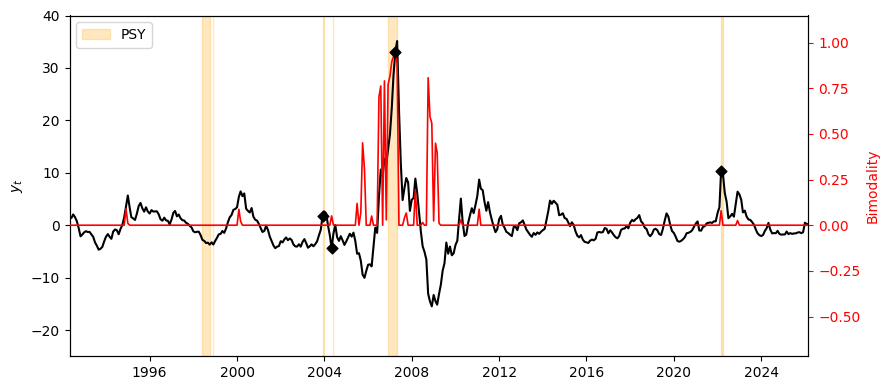

In [10]:
plot_bimodality_and_series_2(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy,
    marker_points=[ 139, 144, 179, 358]
)

### Predictive Density at selected points

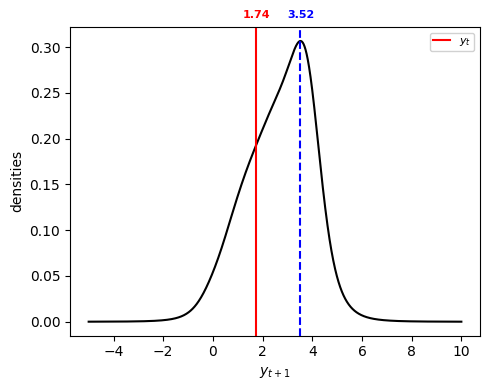

In [11]:
t0 = 141

grid1 = np.linspace(-5, 10, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}"
)

plt.tight_layout()
plt.show()

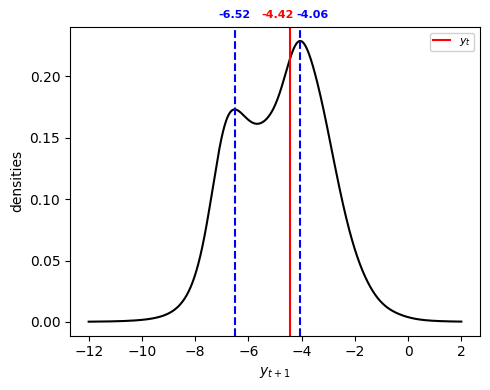

In [12]:
t0 = 146

grid1 = np.linspace(-12, 2, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}"
)

plt.tight_layout()
plt.show()

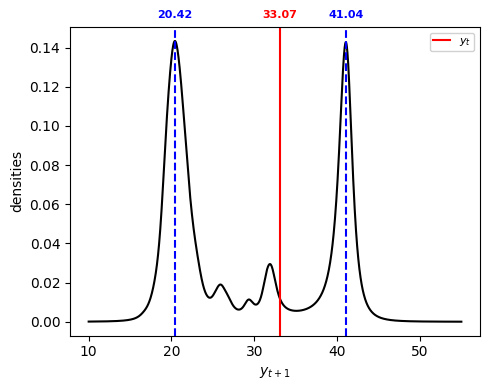

In [13]:
t0 = 181

grid1 = np.linspace(10, 55, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}"
)

plt.tight_layout()
plt.show()

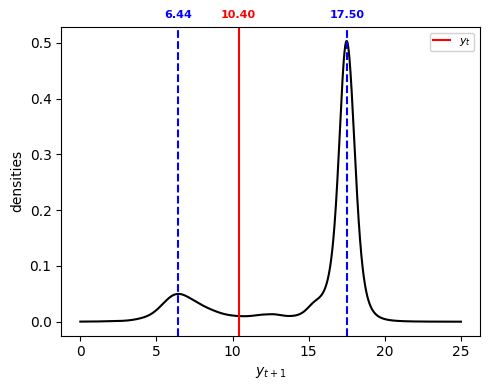

In [14]:
t0 = 360

grid1 = np.linspace(0, 25, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}"
)

plt.tight_layout()
plt.show()

----
## MARX(1,1,3) with Student-t Innovations 

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -607.1945962705404

Estimated parameters:
phi             =     0.5469 (0.0289)
psi             =     0.6757 (0.0381)
beta_copper     =     0.1216 (0.0160)
sigma           =     0.6089 (0.0453)
nu              =     1.9066 (0.2465)

Hessian condition number:
495.11376123815853

Eigenvalues of Hessian:
[8034.17447282 1240.24817619  623.32214665  840.25003999   16.22692622]

MLE diagnostics

--- MARX model diagnostics ---
Log-likelihood: -607.194596
AIC:            1224.389193
BIC:            1244.433258
R^2:            0.919407

Autocorrelation tests (standardized residuals):
  n       = 407
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 0.630715, p-value = 0.427093
    lag  5: statistic = 7.980401, p-value = 0.157319
    lag 10: statistic = 13.275640, p-value = 0.208666
    lag 20: statistic = 37.570660, p-value = 0.00998766

Autocorrelation tests (squared standardized residuals):
  n       = 407
  Ljung-Box (H0: no 

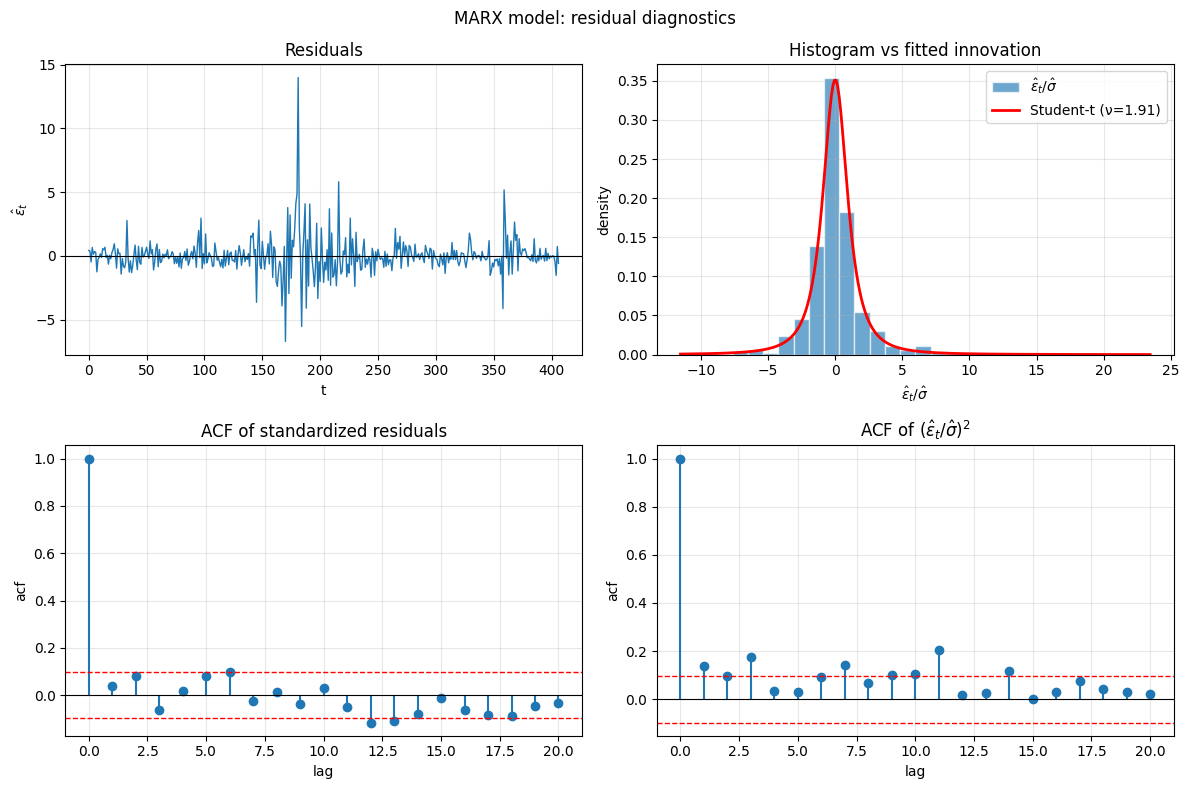

In [15]:
param_names = [ "phi", "psi", "beta_copper", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (1e-6, None),
    (0.1, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_marx,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]

### Sample-Based Predictive Density

$$
\hat l(u_{T+1}\mid u_T, X_T)
=
g(u_T-\psi u_{T+1} - \beta X_T)
\,
\frac{
\sum_{t=1}^{T} g(u_{T+1}-\psi u_t - \beta X_{T+1})
}{
\sum_{t=1}^{T} g(u_T-\psi u_t - \beta X_T)
}
$$

$$
g(e)
=
\frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}
{\Gamma\!\left(\frac{\nu}{2}\right)\sqrt{\nu\pi}\,\sigma}
\left(
1+\frac{e^2}{\nu\sigma^2}
\right)^{-\frac{\nu+1}{2}}
$$

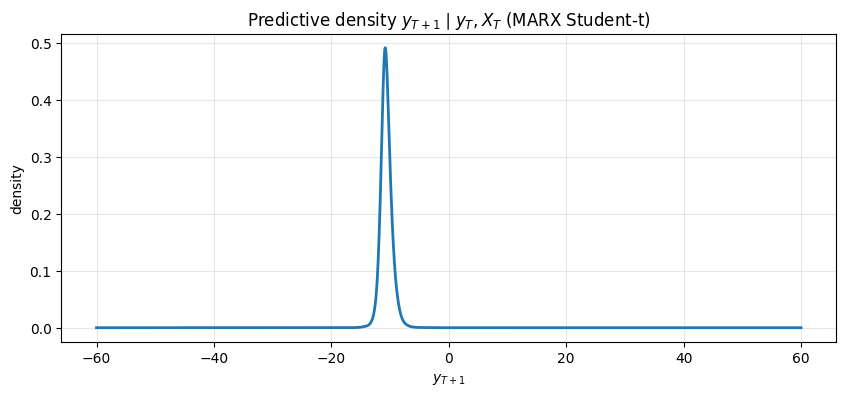

In [16]:
dens = plot_predictive_density(
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t1,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX Student-t)")

### Bimodality

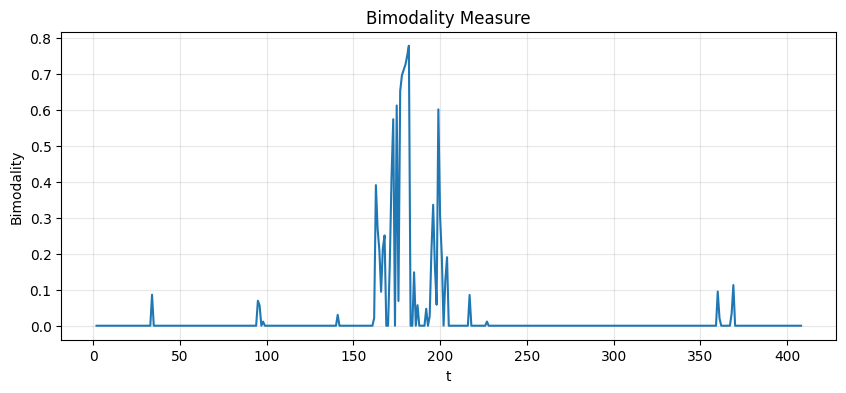

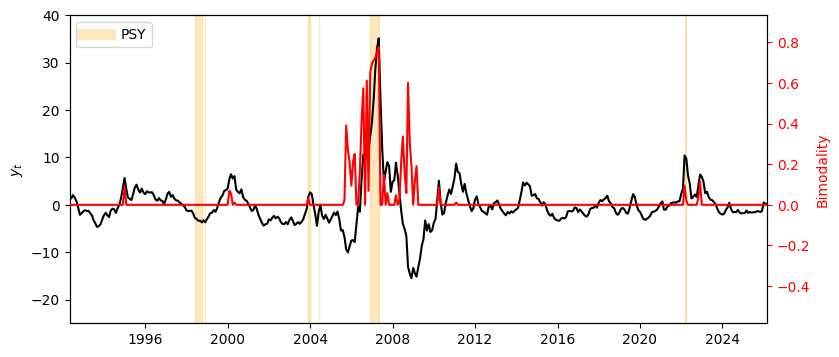

In [17]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_studentt_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


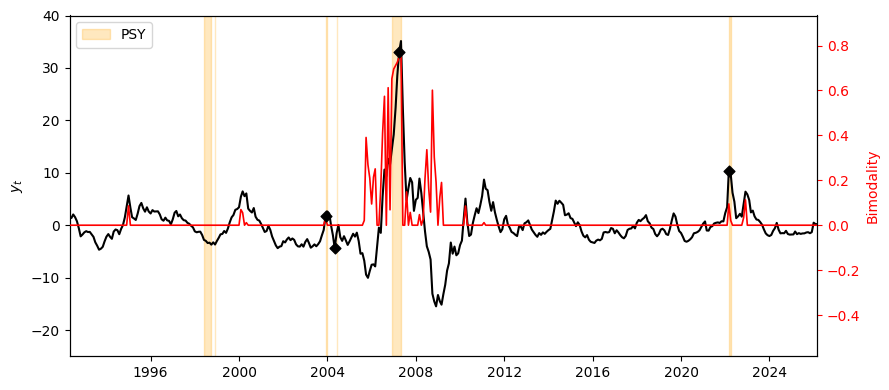

In [18]:
plot_bimodality_and_series_2(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy,
    marker_points=[ 139, 144, 179, 358]
)

### Predictive Density at selected points

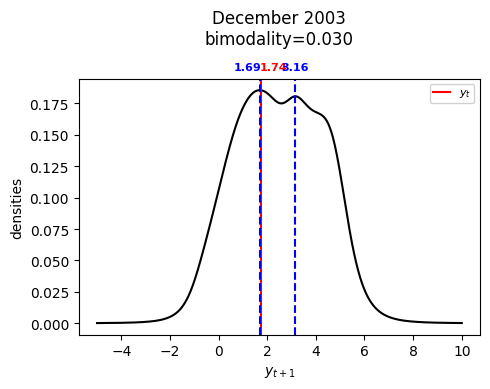

In [19]:
t0 = 141

grid1 = np.linspace(-5, 10, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params,
    title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}"
)

plt.tight_layout()
plt.show()

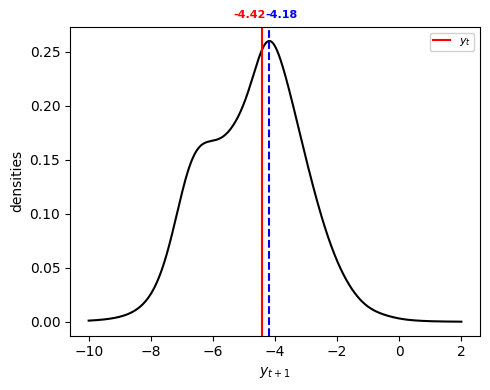

In [20]:
t0 = 146

grid1 = np.linspace(-10, 2, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}"
)

plt.tight_layout()
plt.show()

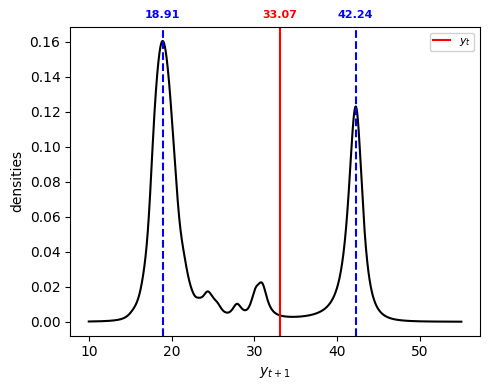

In [21]:
t0 = 181

grid1 = np.linspace(10, 55, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}"
)

plt.tight_layout()
plt.show()

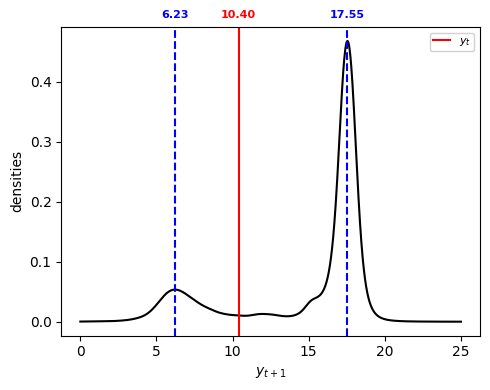

In [22]:
t0 = 360

grid1 = np.linspace(0, 25, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}"
)

plt.tight_layout()
plt.show()

### Bimodality/ Predictive Density changes for different X values

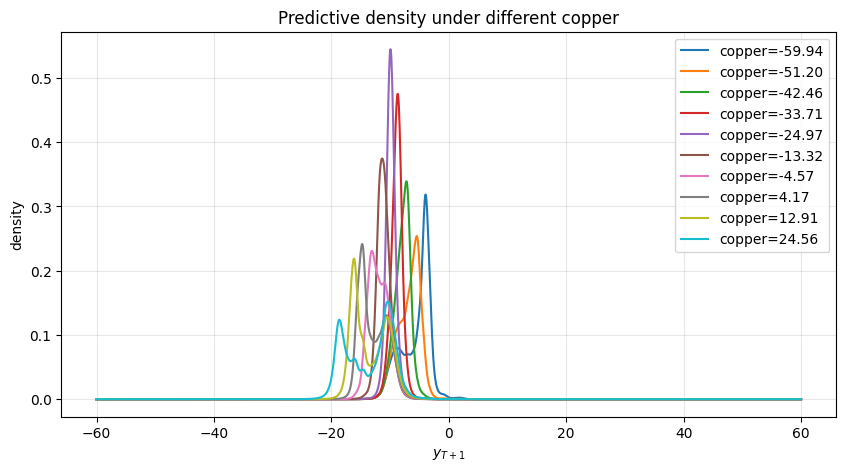

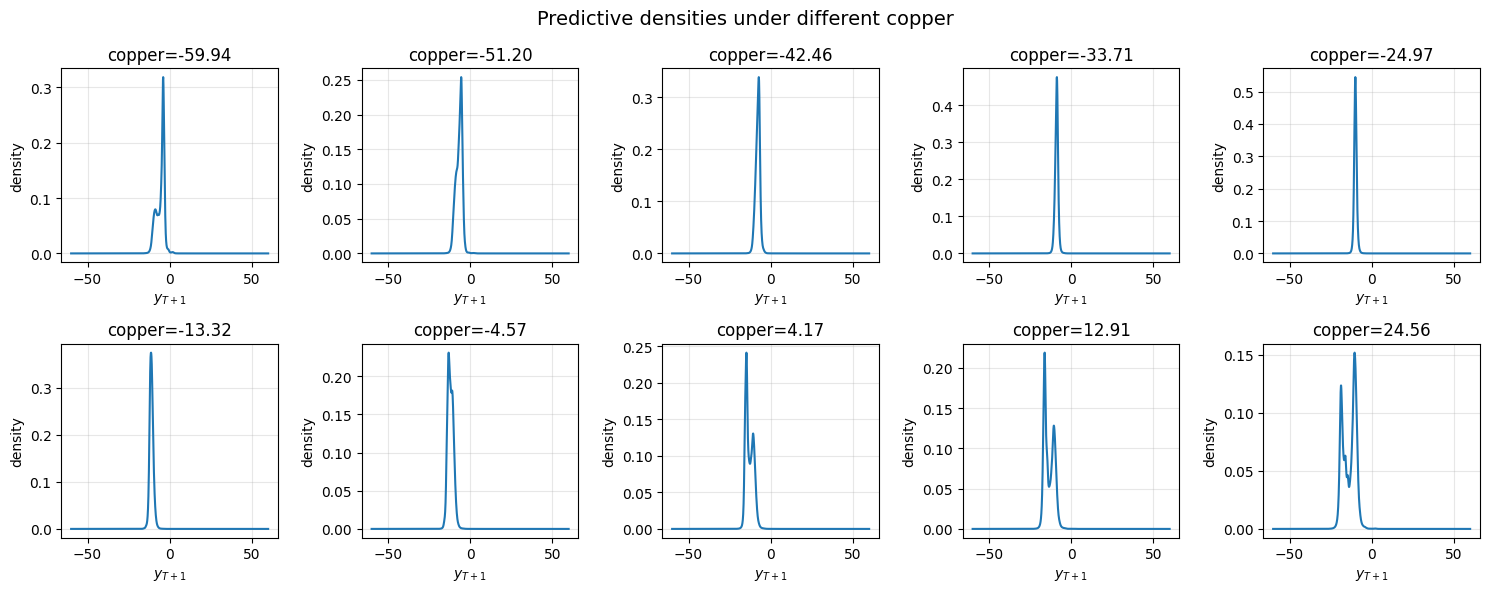

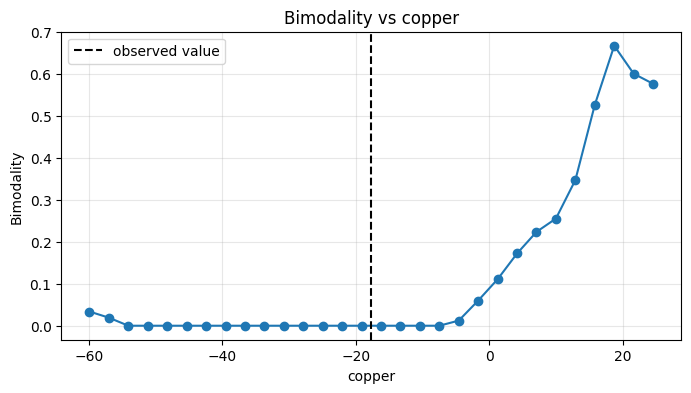

In [23]:
res = shock_analysis(
    var_idx=0,
    X=X,
    y=y,
    params=params,
    predictive_density_fn=marx_studentt_pred_density,
    grid_y=grid,
    n_std=std,
    n_values=values,
    var_names=var,
    t_last=t1,
    prominence_factor=prominence
)
